# Model training

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor 

from scipy import stats

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, roc_curve, RocCurveDisplay, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

import joblib

# needed for the pipeline transformer
import sys
sys.path.append(str(Path().cwd().parents[0] / "src"))
from components.transformations import calculate_deviations

In [2]:
data_location = Path().cwd().parent / "src" / "artifacts" / "data"

In [3]:
df = pd.read_csv(data_location / "baseline_data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [4]:
# creating the baseline dataset
X = df.drop(["id", "diagnosis"], axis=1)
y_raw = df.pop("diagnosis")

In [5]:
y_raw.unique()

<ArrowStringArray>
['M', 'B']
Length: 2, dtype: str

In [6]:
# splitting the data
# raw = uses labels as B and M
X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y_raw, test_size=0.2, stratify=y_raw, shuffle=True)#, random_state=42)

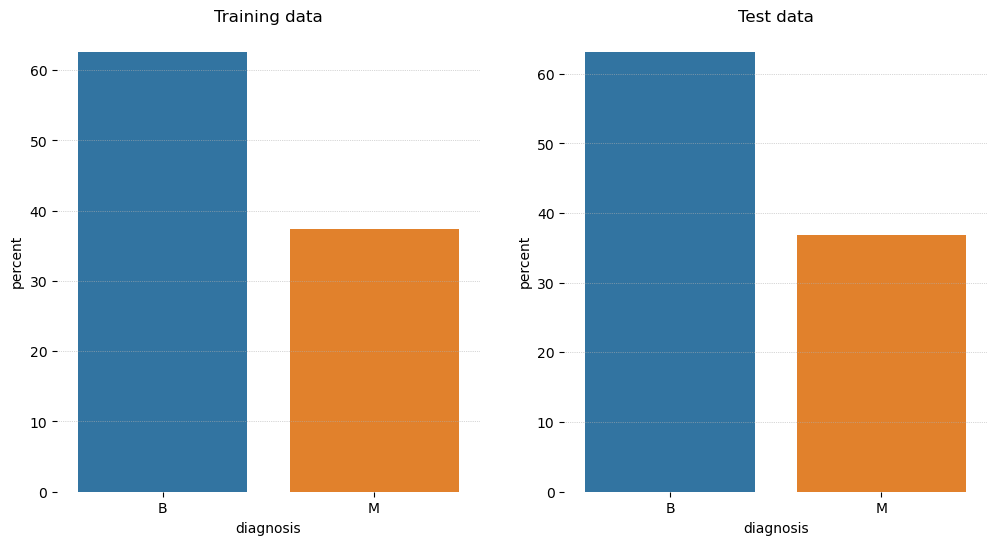

In [7]:
fig, axs = plt.subplots(figsize=(12,6), nrows=1, ncols=2)
sns.countplot(x=y_train_raw.sort_values(), stat="percent", hue=y_train_raw.sort_values(), ax=axs[0])
axs[0].set_title("Training data")
sns.countplot(x=y_test_raw.sort_values(),  stat="percent", hue=y_test_raw.sort_values(),  ax=axs[1])
axs[1].set_title("Test data")
for ax in axs:
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
    ax.grid(True, linewidth=0.5, linestyle=':', axis="y")

In [8]:
print(X_train.shape)
print(X_test.shape)

(455, 30)
(114, 30)


In [9]:
# encode labels
label_encoder = LabelEncoder()
y_train = pd.Series(label_encoder.fit_transform(y_train_raw), index=y_train_raw.index, name="y_train")
y_test = pd.Series(label_encoder.transform(y_test_raw), index=y_test_raw.index, name="y_test")

In [10]:
# labels
labels = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
)
labels

{'B': np.int64(0), 'M': np.int64(1)}

# Baselines

The following models are investigated as baselines for the task.  
Keeping all features in the dataset, what are the most promising models regarding performance and interpretability?

In [11]:
def run_pipeline(X, y, model, return_scores=False):

    # cross validation strategy
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    
    model_name, model_type = model
    
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        (model_name, model_type)
    ])

    if hasattr(model_type, "predict_proba"):
        method = "predict_proba"
        cv_scores = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba", n_jobs=-1, verbose=3)
        y_pred = cv_scores.argmax(axis=1)

        if return_scores:
            return cv_scores[:,1], y_pred

        return {
        "model"     : model_name,
        "method"    : method,
        "precision" : precision_score(y_pred=y_pred, y_true=y),
        "recall"    : recall_score(y_pred=y_pred, y_true=y),
        "f1_score"  : f1_score(y_pred=y_pred, y_true=y),
        "roc_auc"   : roc_auc_score(y_true=y, y_score=cv_scores[:,1])
    }
        
    else:
        # All methods investigatated have a predict_proba method
        # in case a new model with a decision_function method is added
        # This must be updated
        method = "decision_function"
        cv_scores = cross_val_predict(pipe, X, y, cv=cv, method="decision_function", n_jobs=-1, verbose=3)

        return {
        "model"     : model_name,
        "method"    : method,
        "precision" : np.nan,
        "recall"    : np.nan,
        "f1_score"  : np.nan,
        "roc_auc"   : np.nan
    }

    

In [12]:
# Baseline models with some defalut parameters
models = [
    ("logistic_regression", LogisticRegression(solver="liblinear", l1_ratio=1, C=1, max_iter=1000)),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean")),
    ("decision_tree", DecisionTreeClassifier(criterion="entropy", max_depth=4, splitter="best")),
    ("forest", RandomForestClassifier(n_estimators=100, criterion="entropy")),
    ("gradient_boosting", GradientBoostingClassifier()),
    ("adaboost", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=4), n_estimators=100)),
    ("support_vector", CalibratedClassifierCV(SVC(C=0.5, kernel="rbf", gamma="auto"), ensemble=False)), # avoid sklearn warning
    ("gaussian_nb", GaussianNB()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(50,50), activation="relu", early_stopping=True, batch_size=64))
]

In [13]:
scores_baseline = []
for model in models:
    score = run_pipeline(X_train, y_train, model)
    scores_baseline.append(score)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    1.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.7s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.8s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out

## Baseline metrics

In [14]:
# Using all features, Logistic Regression, support vector machines and KNN seem to be the most promesing models
# They already achieve high performance but interprertability is difficult
metrics_baseline = pd.DataFrame(scores_baseline).sort_values("f1_score", ascending=False, ignore_index=True)
metrics_baseline

,model,method,precision,recall,f1_score,roc_auc
0,logistic_regression,predict_proba,0.970238,0.958824,0.964497,0.992136
1,adaboost,predict_proba,0.947059,0.947059,0.947059,0.980454
2,support_vector,predict_proba,0.947059,0.947059,0.947059,0.988854
3,forest,predict_proba,0.952096,0.935294,0.943620,0.987492
4,gradient_boosting,predict_proba,0.920455,0.952941,0.936416,0.984654
5,knn,predict_proba,0.974522,0.900000,0.935780,0.980165
6,decision_tree,predict_proba,0.900585,0.905882,0.903226,0.937430
7,gaussian_nb,predict_proba,0.915152,0.888235,0.901493,0.980010
8,mlp,predict_proba,0.915152,0.888235,0.901493,0.973602


# Feature selection

## Welch's test (ANOVA)
Since we are dealing with only two features, we can use a Welch's test instead of ANOVA to see whether there are any differences between the benign and maligant tumors for each feature.

In [15]:
# merge the data again to use the label for grouping
X_for_feature_selection = pd.merge(X_train, y_train, left_index=True, right_index=True)
X_for_feature_selection.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,y_train
58,13.05,19.31,82.61,527.2,0.08060,0.03789,0.000692,0.004167,0.1819,0.05501,...,22.25,90.24,624.1,0.10210,0.06191,0.001845,0.01111,0.2439,0.06289,0
337,18.77,21.43,122.90,1092.0,0.09116,0.14020,0.106000,0.060900,0.1953,0.06083,...,34.37,161.10,1873.0,0.14980,0.48270,0.463400,0.20480,0.3679,0.09870,1
354,11.14,14.07,71.24,384.6,0.07274,0.06064,0.045050,0.014710,0.1690,0.06083,...,15.82,79.62,453.5,0.08864,0.12560,0.120100,0.03922,0.2576,0.07018,0
482,13.47,14.06,87.32,546.3,0.10710,0.11550,0.057860,0.052660,0.1779,0.06639,...,18.32,94.94,660.2,0.13930,0.24990,0.184800,0.13350,0.3227,0.09326,0
509,15.46,23.95,103.80,731.3,0.11830,0.18700,0.203000,0.085200,0.1807,0.07083,...,36.33,117.70,909.4,0.17320,0.49670,0.591100,0.21630,0.3013,0.10670,1


In [16]:
# separte into two groups B and M
benign    = X_for_feature_selection[X_for_feature_selection["y_train"] == 0]
malignant = X_for_feature_selection[X_for_feature_selection["y_train"] == 1] # This is the positive class what we want to detect

In [17]:
display(benign.head())
display(malignant.head())

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,y_train
58,13.05,19.31,82.61,527.2,0.08060,0.03789,0.000692,0.004167,0.1819,0.05501,...,22.25,90.24,624.1,0.10210,0.06191,0.001845,0.01111,0.2439,0.06289,0
354,11.14,14.07,71.24,384.6,0.07274,0.06064,0.045050,0.014710,0.1690,0.06083,...,15.82,79.62,453.5,0.08864,0.12560,0.120100,0.03922,0.2576,0.07018,0
482,13.47,14.06,87.32,546.3,0.10710,0.11550,0.057860,0.052660,0.1779,0.06639,...,18.32,94.94,660.2,0.13930,0.24990,0.184800,0.13350,0.3227,0.09326,0
407,12.85,21.37,82.63,514.5,0.07551,0.08316,0.061260,0.018670,0.1580,0.06114,...,27.01,91.63,645.8,0.09402,0.19360,0.183800,0.05601,0.2488,0.08151,0
111,12.63,20.76,82.15,480.4,0.09933,0.12090,0.106500,0.060210,0.1735,0.07070,...,25.47,89.00,527.4,0.12870,0.22500,0.221600,0.11050,0.2226,0.08486,0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,y_train
337,18.77,21.43,122.90,1092.0,0.09116,0.1402,0.1060,0.06090,0.1953,0.06083,...,34.37,161.1,1873.0,0.1498,0.4827,0.4634,0.2048,0.3679,0.09870,1
509,15.46,23.95,103.80,731.3,0.11830,0.1870,0.2030,0.08520,0.1807,0.07083,...,36.33,117.7,909.4,0.1732,0.4967,0.5911,0.2163,0.3013,0.10670,1
351,15.75,19.22,107.10,758.6,0.12430,0.2364,0.2914,0.12420,0.2375,0.07603,...,24.17,119.4,915.3,0.1550,0.5046,0.6872,0.2135,0.4245,0.10500,1
213,17.42,25.56,114.50,948.0,0.10060,0.1146,0.1682,0.06597,0.1308,0.05866,...,28.07,120.4,1021.0,0.1243,0.1793,0.2803,0.1099,0.1603,0.06818,1
26,14.58,21.53,97.41,644.8,0.10540,0.1868,0.1425,0.08783,0.2252,0.06924,...,33.21,122.4,896.9,0.1525,0.6643,0.5539,0.2701,0.4264,0.12750,1


In [18]:
def run_ttests(df1, df2):
    _, n_features = df1.shape
    results = {"feature" : [], "t_statistic" : [], "p_value_t" : []}
    for feature in df1.columns:
        # skip the label
        if feature == "y_train":
            continue
        # perform t-tests, covariance matrix shows the variances for both groups are different
        # so we use unequal variances
        t_statistic, p_value_t = stats.ttest_ind(df1[feature], df2[feature], equal_var=False, alternative="two-sided")
        results["feature"].append(feature)
        results["t_statistic"].append(t_statistic)
        results["p_value_t"].append(p_value_t)
        
    df = pd.DataFrame(results).sort_values(by=["p_value_t"], ascending=True, ignore_index=True)
    # adjust p-values using benjamini-hochberg
    df["p_value_bh_adjusted"] = stats.false_discovery_control(df["p_value_t"])
    # run bonferri comparison
    df["comparison_bonferri"] = df["p_value_t"].lt(0.05/n_features)
    # run bh comparison to see which hypothesis can be rejected
    df["comparison_bh"]       = df["p_value_bh_adjusted"].lt(0.05)

    return df

In [19]:
df_ttest = run_ttests(benign, malignant)
df_ttest

,feature,t_statistic,p_value_t,p_value_bh_adjusted,comparison_bonferri,comparison_bh
0,concave_points_worst,-26.536488,9.349629e-82,2.804889e-80,True,True
1,perimeter_worst,-22.989446,8.109735e-60,1.216460e-58,True,True
2,concave_points_mean,-22.626196,4.422947e-59,4.422947e-58,True,True
3,radius_worst,-22.444231,2.774114e-58,2.080586e-57,True,True
4,perimeter_mean,-20.432479,1.343378e-53,8.060268e-53,True,True
5,radius_mean,-19.710118,1.506271e-51,7.531353e-51,True,True
6,concavity_mean,-18.431491,1.858329e-47,7.964266e-47,True,True
7,concavity_worst,-17.233105,1.588636e-46,5.957386e-46,True,True
8,area_worst,-18.439355,9.746013e-44,3.248671e-43,True,True
9,area_mean,-17.344478,1.892994e-41,5.678983e-41,True,True


In [20]:
features_to_remove = df_ttest[(~df_ttest["comparison_bonferri"]) & (~df_ttest["comparison_bh"])].loc[:, "feature"].tolist()
features_to_remove

['fractal_dimension_se',
 'smoothness_se',
 'symmetry_se',
 'texture_se',
 'fractal_dimension_mean']

In [21]:
X_train_after_fs = X_train.drop(features_to_remove, axis=1)
X_train_after_fs.shape

(455, 25)

## Variance Inflation Factor

In [22]:
def get_vif(X):
    features_column = []
    vif_column = []
    for idx, feature in enumerate(X.columns):
        features_column.append(feature)
        vif_column.append(variance_inflation_factor(X, idx))
    
    df_vif = pd.DataFrame(
        {
            "features" : features_column,
            "vif" : vif_column
        }
    )
    return df_vif.sort_values(by="vif", ascending=False, ignore_index=True)

In [23]:
print(get_vif(X_train_after_fs))

                   features          vif
0               radius_mean  4072.585246
1            perimeter_mean  4004.195571
2              radius_worst   767.159659
3           perimeter_worst   377.993393
4                 area_mean   325.156695
5                area_worst   309.078010
6                 radius_se    71.513265
7              perimeter_se    64.830159
8            concavity_mean    63.262709
9       concave_points_mean    55.583594
10                  area_se    41.950359
11          concavity_worst    38.353010
12         compactness_mean    35.662011
13     concave_points_worst    34.243383
14        compactness_worst    31.449319
15             concavity_se    18.412122
16           compactness_se    12.671574
17        concave_points_se    11.214613
18            texture_worst     9.624257
19             texture_mean     8.821552
20          smoothness_mean     7.417529
21         smoothness_worst     6.544824
22  fractal_dimension_worst     6.046251
23           sym

## Model candidates
What is the performance of the candidate models after removing the features?

In [24]:
scores_after_fs = []
for model in models:
    score = run_pipeline(X_train_after_fs, y_train, model)
    scores_after_fs.append(score)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.7s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out

## Feature selection metrics

In [25]:
metrics_after_fs = pd.DataFrame(scores_after_fs).sort_values("f1_score", ascending=False, ignore_index=True)
metrics_after_fs

,model,method,precision,recall,f1_score,roc_auc
0,logistic_regression,predict_proba,0.970060,0.952941,0.961424,0.992693
1,support_vector,predict_proba,0.964072,0.947059,0.955490,0.990836
2,forest,predict_proba,0.958084,0.941176,0.949555,0.984995
3,adaboost,predict_proba,0.946746,0.941176,0.943953,0.979763
4,knn,predict_proba,0.980892,0.905882,0.941896,0.979370
5,gradient_boosting,predict_proba,0.925287,0.947059,0.936047,0.984551
6,decision_tree,predict_proba,0.905882,0.905882,0.905882,0.934572
7,gaussian_nb,predict_proba,0.904192,0.888235,0.896142,0.979783
8,mlp,predict_proba,0.959184,0.829412,0.889590,0.969515


# Feature Engineering
Some of the features share a geometrics interpretation we can use to derive possible usefull features

In [26]:
X_train_after_fs.columns.sort_values().tolist()

['area_mean',
 'area_se',
 'area_worst',
 'compactness_mean',
 'compactness_se',
 'compactness_worst',
 'concave_points_mean',
 'concave_points_se',
 'concave_points_worst',
 'concavity_mean',
 'concavity_se',
 'concavity_worst',
 'fractal_dimension_worst',
 'perimeter_mean',
 'perimeter_se',
 'perimeter_worst',
 'radius_mean',
 'radius_se',
 'radius_worst',
 'smoothness_mean',
 'smoothness_worst',
 'symmetry_mean',
 'symmetry_worst',
 'texture_mean',
 'texture_worst']

In [27]:
X_train_reduced = X_train_after_fs.drop(["perimeter_mean", "perimeter_worst", "perimeter_se", "radius_mean", "radius_worst", "radius_se"], axis=1)
X_train_reduced.shape

(455, 19)

In [28]:
X_train_reduced.columns.sort_values()

Index(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_se', 'compactness_worst', 'concave_points_mean',
       'concave_points_se', 'concave_points_worst', 'concavity_mean',
       'concavity_se', 'concavity_worst', 'fractal_dimension_worst',
       'smoothness_mean', 'smoothness_worst', 'symmetry_mean',
       'symmetry_worst', 'texture_mean', 'texture_worst'],
      dtype='str')

In [29]:
for feature in X_train_reduced.columns:
    # ignore SE for the moment
    if feature.endswith("_se"):
        continue
    feature_name_template = feature.replace("_mean", "")
    feature_worst = f"{feature_name_template}_worst"
    # Both mean and worstmust be in the columns
    if feature_worst not in X_train_reduced.columns:
        continue
    
    if X_train_reduced[feature].eq(0).any():
        continue
        #X_train_reduced[f"{feature_name_template}_deaviation_abs"] = X_train_reduced.apply(
        #    lambda row: (row[f"{feature_name_template}_worst"] - row[f"{feature_name_template}_mean"]), axis=1
        #)
    else:
        X_train_reduced[f"{feature_name_template}_deviation_relative"] = X_train_reduced.apply(
            lambda row: (row[f"{feature_name_template}_worst"] - row[f"{feature_name_template}_mean"])/row[f"{feature_name_template}_mean"], axis=1
        )
    X_train_reduced = X_train_reduced.drop([feature_worst], axis=1)
X_train_reduced.shape

(455, 19)

In [30]:
X_train_reduced.columns.sort_values()

Index(['area_deviation_relative', 'area_mean', 'area_se',
       'compactness_deviation_relative', 'compactness_mean', 'compactness_se',
       'concave_points_mean', 'concave_points_se', 'concave_points_worst',
       'concavity_mean', 'concavity_se', 'concavity_worst',
       'fractal_dimension_worst', 'smoothness_deviation_relative',
       'smoothness_mean', 'symmetry_deviation_relative', 'symmetry_mean',
       'texture_deviation_relative', 'texture_mean'],
      dtype='str')

In [31]:
X_train_engineered = X_train_reduced.drop(
    [
        'fractal_dimension_worst',
        'concave_points_mean',
        'concave_points_se',
        'concave_points_worst',
        'concavity_mean',
        'concavity_se',
        'concavity_worst',
    ], axis=1
)


In [32]:
X_train_engineered.shape

(455, 12)

In [33]:
X_train_engineered.columns.sort_values().to_list()

['area_deviation_relative',
 'area_mean',
 'area_se',
 'compactness_deviation_relative',
 'compactness_mean',
 'compactness_se',
 'smoothness_deviation_relative',
 'smoothness_mean',
 'symmetry_deviation_relative',
 'symmetry_mean',
 'texture_deviation_relative',
 'texture_mean']

In [34]:
benign_and_malignant = pd.merge(X_train_engineered, y_train, left_index=True, right_index=True)
benign    = benign_and_malignant[benign_and_malignant["y_train"] == 0]
malignant = benign_and_malignant[benign_and_malignant["y_train"] == 1]
display(benign.head())
display(malignant.head())

,texture_mean,area_mean,smoothness_mean,compactness_mean,symmetry_mean,area_se,compactness_se,texture_deviation_relative,area_deviation_relative,smoothness_deviation_relative,compactness_deviation_relative,symmetry_deviation_relative,y_train
58,19.31,527.2,0.08060,0.03789,0.1819,32.96,0.008593,0.152253,0.183801,0.266749,0.633940,0.340847,0
354,14.07,384.6,0.07274,0.06064,0.1690,28.84,0.033870,0.124378,0.179147,0.218587,1.071240,0.524260,0
482,14.06,546.3,0.10710,0.11550,0.1779,12.84,0.014520,0.302987,0.208494,0.300654,1.163636,0.813940,0
407,21.37,514.5,0.07551,0.08316,0.1580,41.24,0.044800,0.263921,0.255199,0.245133,1.328042,0.574684,0
111,20.76,480.4,0.09933,0.12090,0.1735,20.48,0.040420,0.226879,0.097835,0.295681,0.861042,0.282997,0


,texture_mean,area_mean,smoothness_mean,compactness_mean,symmetry_mean,area_se,compactness_se,texture_deviation_relative,area_deviation_relative,smoothness_deviation_relative,compactness_deviation_relative,symmetry_deviation_relative,y_train
337,21.43,1092.0,0.09116,0.1402,0.1953,88.25,0.03897,0.603826,0.715201,0.643265,2.442939,0.883769,1
509,23.95,731.3,0.11830,0.1870,0.1807,32.52,0.04940,0.516910,0.243539,0.464074,1.656150,0.667405,1
351,19.22,758.6,0.12430,0.2364,0.2375,51.22,0.06559,0.257544,0.206565,0.246983,1.134518,0.787368,1
213,25.56,948.0,0.10060,0.1146,0.1308,58.53,0.08555,0.098200,0.077004,0.235586,0.564572,0.225535,1
26,21.53,644.8,0.10540,0.1868,0.2252,21.05,0.03055,0.542499,0.390974,0.446869,2.556210,0.893428,1


In [35]:
run_ttests(benign, malignant)

,feature,t_statistic,p_value_t,p_value_bh_adjusted,comparison_bonferri,comparison_bh
0,area_mean,-17.344478,1.892994e-41,2.271593e-40,True,True
1,compactness_mean,-14.419770,3.855410e-35,2.313246e-34,True,True
2,area_deviation_relative,-14.177668,7.030772e-32,2.812309e-31,True,True
3,area_se,-10.373796,6.634092e-20,1.990228e-19,True,True
4,texture_mean,-9.438334,5.050869e-19,1.212209e-18,True,True
5,smoothness_mean,-8.258996,2.633641e-15,5.267281e-15,True,True
6,symmetry_mean,-6.882486,2.907212e-11,4.983792e-11,True,True
7,compactness_se,-6.511023,2.652804e-10,3.979207e-10,True,True
8,compactness_deviation_relative,-5.288181,2.210350e-07,2.947134e-07,True,True
9,smoothness_deviation_relative,-4.596003,6.141332e-06,7.369598e-06,True,True


In [36]:
get_vif(X_train_engineered)

,features,vif
0,compactness_mean,7.681672
1,area_mean,4.053280
2,area_se,4.004977
3,compactness_se,3.802039
4,smoothness_mean,2.804389
5,compactness_deviation_relative,2.582065
6,area_deviation_relative,2.326476
7,symmetry_deviation_relative,1.934170
8,smoothness_deviation_relative,1.861779
9,symmetry_mean,1.812185


In [37]:
scores_engineered = []
for model in models:
    score = run_pipeline(X_train_engineered, y_train, model)
    scores_engineered.append(score)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out

## Feature Engineering metrics

In [38]:
metrics_engineered = pd.DataFrame(scores_engineered).sort_values("f1_score", ascending=False, ignore_index=True)
metrics_engineered

,model,method,precision,recall,f1_score,roc_auc
0,logistic_regression,predict_proba,0.969697,0.941176,0.955224,0.992528
1,adaboost,predict_proba,0.963415,0.929412,0.946108,0.991166
2,forest,predict_proba,0.981013,0.911765,0.945122,0.992642
3,support_vector,predict_proba,0.957317,0.923529,0.940120,0.987451
4,gradient_boosting,predict_proba,0.957055,0.917647,0.936937,0.988916
5,gaussian_nb,predict_proba,0.917160,0.911765,0.914454,0.985944
6,knn,predict_proba,0.979310,0.835294,0.901587,0.968720
7,decision_tree,predict_proba,0.946667,0.835294,0.887500,0.931042
8,mlp,predict_proba,0.914062,0.688235,0.785235,0.947472


## Feature Engineering Pipeline

In [39]:
# SKIP THIS
# Once all decision about what features to keep are made we need a deterministc pipeline for all datasets
#def calculate_deviations(df:pd.DataFrame) -> pd.DataFrame:

#    features = ["area", "compactness", "smoothness", "symmetry", "texture"]
#    features_to_drop = ["perimeter_mean", "perimeter_worst", "perimeter_se", "radius_mean", "radius_worst", "radius_se"]

#    X = df.drop(features_to_drop, axis=1)

#    transformed = {}
#    for feature in features:
#        transformed[f"{feature}_mean"] = X.loc[:, f"{feature}_mean"]
#        transformed[f"{feature}_deviation_relative"] = (X.loc[:, f"{feature}_worst"] - X.loc[:, f"{feature}_mean"]) / X.loc[:, f"{feature}_mean"]

#    for feature in features[:2]:
#        transformed.update(
#            {
#                f"{feature}_se" : X.loc[:, f"{feature}_se"]
#           }
#        )

#    return pd.DataFrame(transformed, index=X.index)

In [40]:
transformer = FunctionTransformer(calculate_deviations)

In [41]:
# The pipeline must take the complete dataset and perform the feature selection and engineering
X_train_transformed = transformer.transform(X_train)

In [42]:
X_train_transformed.shape

(455, 12)

In [43]:
X_train_transformed.columns.sort_values()

Index(['area_deviation_relative', 'area_mean', 'area_se',
       'compactness_deviation_relative', 'compactness_mean', 'compactness_se',
       'smoothness_deviation_relative', 'smoothness_mean',
       'symmetry_deviation_relative', 'symmetry_mean',
       'texture_deviation_relative', 'texture_mean'],
      dtype='str')

In [44]:
X_train_engineered.columns.sort_values()

Index(['area_deviation_relative', 'area_mean', 'area_se',
       'compactness_deviation_relative', 'compactness_mean', 'compactness_se',
       'smoothness_deviation_relative', 'smoothness_mean',
       'symmetry_deviation_relative', 'symmetry_mean',
       'texture_deviation_relative', 'texture_mean'],
      dtype='str')

In [45]:
X_train_transformed.columns.sort_values() == X_train_engineered.columns.sort_values()

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

# Evaluating best models

In [46]:
logistic_reg = [model for model in models if model[0]=="logistic_regression"][0]
logistic_scores, y_pred_logistc = run_pipeline(X_train_engineered, y_train, logistic_reg, return_scores=True)

svm = [model for model in models if model[0]=="support_vector"][0]
svm_scores, y_pred_svm = run_pipeline(X_train_engineered, y_train, svm, return_scores=True)

forest = [model for model in models if model[0]=="forest"][0]
forest_scores, y_pred_forest = run_pipeline(X_train_engineered, y_train, forest, return_scores=True)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    0.1s finished


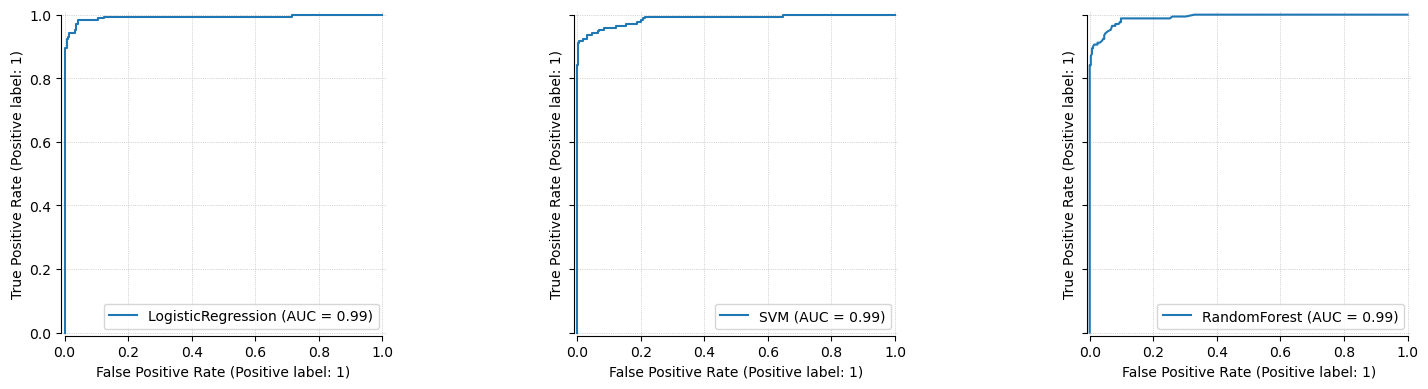

In [47]:
fig, axs = plt.subplots(figsize=(16,4), nrows=1, ncols=3, sharex=True, sharey=True)

RocCurveDisplay.from_predictions(y_train, logistic_scores, ax=axs[0], despine=True, name="LogisticRegression")
RocCurveDisplay.from_predictions(y_train, svm_scores,      ax=axs[1], despine=True, name="SVM")
RocCurveDisplay.from_predictions(y_train, forest_scores,   ax=axs[2], despine=True, name="RandomForest")

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

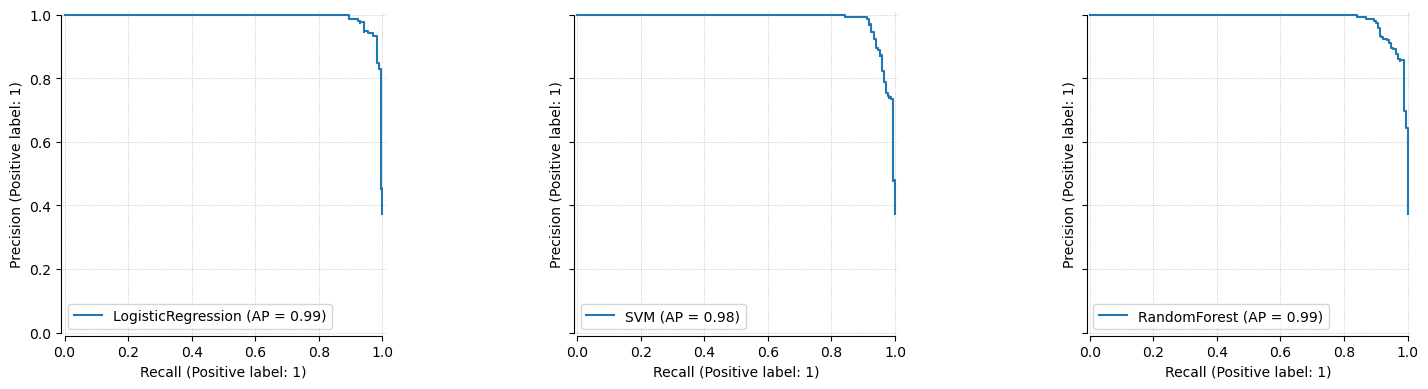

In [48]:
fig, axs = plt.subplots(figsize=(16,4), nrows=1, ncols=3, sharex=True, sharey=True)

PrecisionRecallDisplay.from_predictions(y_train, logistic_scores, ax=axs[0], despine=True, name="LogisticRegression")
PrecisionRecallDisplay.from_predictions(y_train, svm_scores,      ax=axs[1], despine=True, name="SVM")
PrecisionRecallDisplay.from_predictions(y_train, forest_scores,   ax=axs[2], despine=True, name="RandomForest")

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

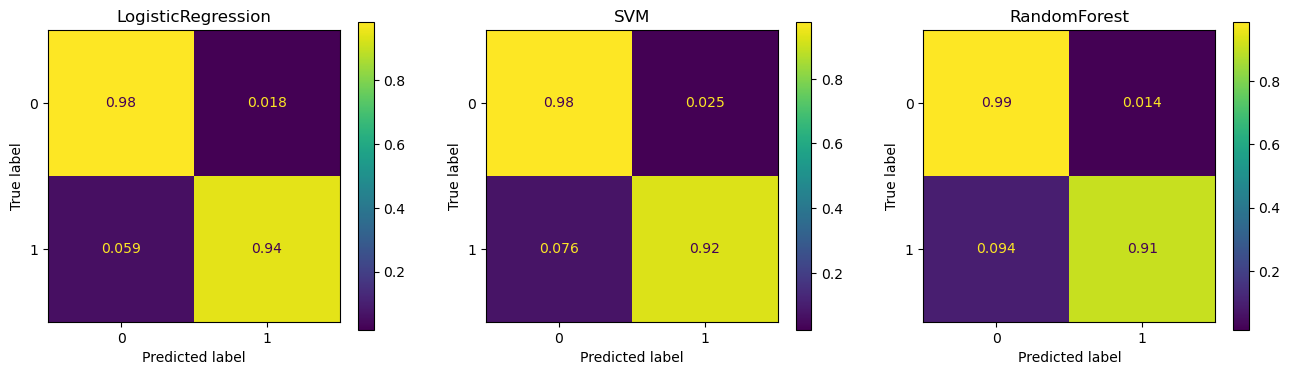

In [49]:
fig, axs = plt.subplots(figsize=(16,4), nrows=1, ncols=3, sharex=True, sharey=False)

ConfusionMatrixDisplay.from_predictions(y_train, y_pred_logistc, ax=axs[0], normalize="true")
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_svm,     ax=axs[1], normalize="true")
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_forest,  ax=axs[2], normalize="true")

for ax, title in zip(axs, ("LogisticRegression", "SVM", "RandomForest")):
    ax.set_title(title)

In [50]:
# Logistic Regression
report = classification_report(y_true=y_train, y_pred=y_pred_logistc)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.98      0.97       285
           1       0.97      0.94      0.96       170

    accuracy                           0.97       455
   macro avg       0.97      0.96      0.96       455
weighted avg       0.97      0.97      0.97       455



In [51]:
# SVM
report = classification_report(y_true=y_train, y_pred=y_pred_svm)
print(report)

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       285
           1       0.96      0.92      0.94       170

    accuracy                           0.96       455
   macro avg       0.96      0.95      0.95       455
weighted avg       0.96      0.96      0.96       455



In [52]:
# Forest
report = classification_report(y_true=y_train, y_pred=y_pred_forest)
print(report)

              precision    recall  f1-score   support

           0       0.95      0.99      0.97       285
           1       0.97      0.91      0.94       170

    accuracy                           0.96       455
   macro avg       0.96      0.95      0.95       455
weighted avg       0.96      0.96      0.96       455



# Hyperparamater tuning

In [53]:
cv = StratifiedKFold(n_splits=3, shuffle=True)

## Logistic Regression

In [54]:
logistic_reg

('logistic_regression',
 LogisticRegression(C=1, l1_ratio=1, max_iter=1000, solver='liblinear'))

In [55]:
logistic_param_distributions = {
    "logistic_regression__C" : np.logspace(-3, 3, 100),
    "logistic_regression__l1_ratio" : np.linspace(0, 1, 51),
    "logistic_regression__solver" : ["saga"],
    "logistic_regression__max_iter" : [10000, 12000]
}

In [56]:
logistic_pipe = Pipeline([
        ("transformer", transformer),
        ("scaler", StandardScaler()),
        logistic_reg
    ])
logistic_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cal...t 0x15a718e00>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictio

In [57]:
logistic_search = RandomizedSearchCV(
    logistic_pipe,
    param_distributions=logistic_param_distributions,
    n_iter=1200,
    cv=cv,
    scoring="f1",
    error_score="raise"
)
logistic_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'logistic_regression__C': array([1.0000...00000000e+03]), 'logistic_regression__l1_ratio': array([0. , ..., 0.98, 1. ]), 'logistic_regression__max_iter': [10000, 12000], 'logistic_regression__solver': ['saga']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",1200
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_es

In [58]:
logistic_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'logistic_regression__C': array([1.0000...00000000e+03]), 'logistic_regression__l1_ratio': array([0. , ..., 0.98, 1. ]), 'logistic_regression__max_iter': [10000, 12000], 'logistic_regression__solver': ['saga']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",1200
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_es

In [59]:
logistic_search.best_score_

np.float64(0.960960960960961)

In [60]:
logistic_best_scores = pd.DataFrame(logistic_search.cv_results_).sort_values(by="mean_test_score", ascending=False)
logistic_best_scores

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_logistic_regression__solver,param_logistic_regression__max_iter,param_logistic_regression__l1_ratio,param_logistic_regression__C,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
959,0.005379,0.000296,0.001240,0.000020,saga,10000,0.98,0.464159,"{'logistic_regression__solver': 'saga', 'logis...",0.954955,0.936937,0.990991,0.960961,0.022472,1
325,0.005263,0.000102,0.001216,0.000014,saga,10000,1.00,0.464159,"{'logistic_regression__solver': 'saga', 'logis...",0.954955,0.936937,0.990991,0.960961,0.022472,1
1081,0.007732,0.000961,0.001482,0.000011,saga,10000,0.98,0.613591,"{'logistic_regression__solver': 'saga', 'logis...",0.946429,0.936937,0.990991,0.958119,0.023565,3
1004,0.009501,0.002176,0.001244,0.000022,saga,10000,0.96,0.811131,"{'logistic_regression__solver': 'saga', 'logis...",0.946429,0.936937,0.990991,0.958119,0.023565,3
603,0.011582,0.003411,0.001430,0.000043,saga,12000,1.00,0.932603,"{'logistic_regression__solver': 'saga', 'logis...",0.946429,0.936937,0.990991,0.958119,0.023565,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,0.001348,0.000014,0.001199,0.000007,saga,12000,0.32,0.001000,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,0.000000,0.000000,0.000000,0.000000,1075
983,0.001364,0.000026,0.001224,0.000022,saga,12000,0.92,0.002656,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,0.000000,0.000000,0.000000,0.000000,1075
538,0.001624,0.000023,0.001468,0.000021,saga,12000,0.80,0.001520,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,0.000000,0.000000,0.000000,0.000000,1075
83,0.001394,0.000023,0.001221,0.000024,saga,10000,0.72,0.003054,"{'logistic_regression__solver': 'saga', 'logis...",0.000000,0.000000,0.000000,0.000000,0.000000,1075


In [61]:
logistic_params = logistic_best_scores["params"][logistic_best_scores["mean_test_score"] >= 0.95].tolist()
logistic_params = pd.DataFrame(logistic_params)
logistic_params

,logistic_regression__solver,logistic_regression__max_iter,logistic_regression__l1_ratio,logistic_regression__C
0,saga,10000,0.98,0.464159
1,saga,10000,1.00,0.464159
2,saga,10000,0.98,0.613591
3,saga,10000,0.96,0.811131
4,saga,12000,1.00,0.932603
...,...,...,...,...
139,saga,10000,0.08,0.151991
140,saga,12000,0.00,0.151991
141,saga,10000,0.02,0.132194
142,saga,12000,0.20,0.151991


In [62]:
artifacts_dir = Path().cwd().parent / "src" / "artifacts" / "models"
artifacts_dir.exists()

True

In [63]:
_ = joblib.dump(logistic_search.best_estimator_, artifacts_dir.joinpath("logistic_regression.joblib"))

In [64]:
best_model = logistic_search.best_estimator_

In [65]:
y_pred_test = best_model.predict(X_test)
y_pred_scores_test = best_model.predict_proba(X_test)[:,1]

In [66]:
# on test data
print(
    classification_report(y_pred=y_pred_test, y_true=y_test)
)

              precision    recall  f1-score   support

           0       0.95      1.00      0.97        72
           1       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



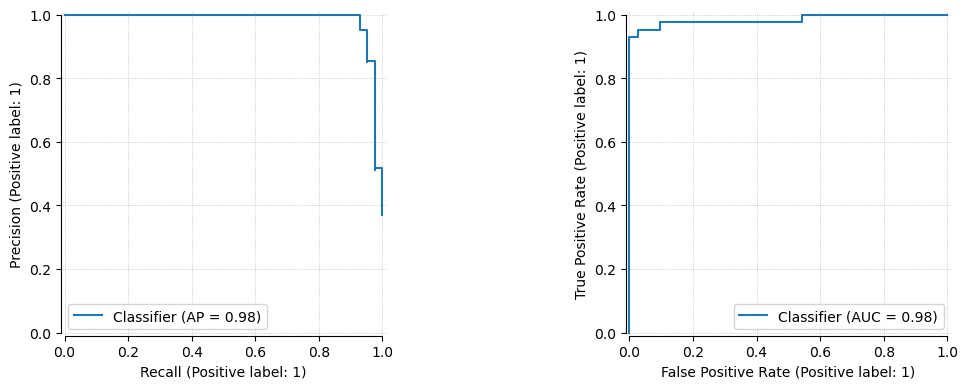

In [67]:
fig, axs = plt.subplots(figsize=(12,4), nrows=1, ncols=2)

PrecisionRecallDisplay.from_predictions(y_true=y_test, y_score=y_pred_scores_test, ax=axs[0], despine=True)
RocCurveDisplay.from_predictions(y_true=y_test, y_score=y_pred_scores_test, ax=axs[1], despine=True)

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

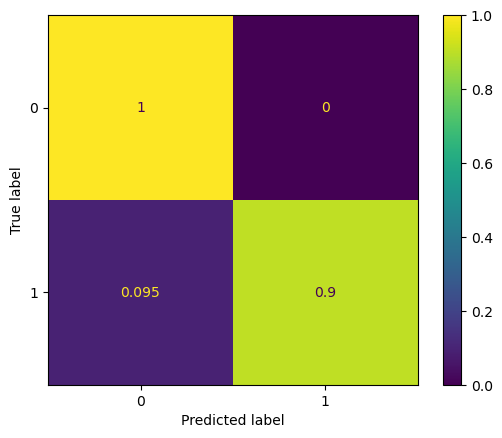

In [68]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, normalize="true")

## Random Forest

In [69]:
forest

('forest', RandomForestClassifier(criterion='entropy'))

In [70]:
forest_param_distributions = {
    "forest__n_estimators" : np.arange(10, 1000, 10),
    "forest__criterion" : ["gini", "entropy"],
    "forest__max_depth" : np.arange(2,22,2),
    "forest__max_features" : [10, "sqrt", None]
}

In [71]:
forest_pipe = Pipeline([
    ("transformer", transformer),
    ("scaler", StandardScaler()),
    forest
])

In [72]:
forest_search = RandomizedSearchCV(
    forest_pipe,
    param_distributions=forest_param_distributions,
    n_iter=1200,
    cv=cv,
    scoring="f1",
    error_score="raise"
)
forest_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...='entropy'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'forest__criterion': ['gini', 'entropy'], 'forest__max_depth': array([ 2, 4..., 16, 18, 20]), 'forest__max_features': [10, 'sqrt', ...], 'forest__n_estimators': array([ 10, ...70, 980, 990])}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",1200
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute

In [73]:
forest_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...='entropy'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'forest__criterion': ['gini', 'entropy'], 'forest__max_depth': array([ 2, 4..., 16, 18, 20]), 'forest__max_features': [10, 'sqrt', ...], 'forest__n_estimators': array([ 10, ...70, 980, 990])}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",1200
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute

In [74]:
forest_search.best_score_

np.float64(0.9543836226079216)

In [75]:
forest_best_scores = pd.DataFrame(forest_search.cv_results_).sort_values(by="mean_test_score", ascending=False)
forest_best_scores

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_forest__n_estimators,param_forest__max_features,param_forest__max_depth,param_forest__criterion,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
558,0.011044,0.000072,0.001960,0.000033,30,sqrt,8,entropy,"{'forest__n_estimators': 30, 'forest__max_feat...",0.946429,0.934579,0.982143,0.954384,0.020216,1
261,0.154009,0.000755,0.010255,0.000080,520,sqrt,14,gini,"{'forest__n_estimators': 520, 'forest__max_fea...",0.947368,0.954128,0.954955,0.952151,0.003398,2
881,0.025317,0.000177,0.002857,0.000064,80,sqrt,12,gini,"{'forest__n_estimators': 80, 'forest__max_feat...",0.938053,0.944444,0.972973,0.951824,0.015181,3
846,0.099025,0.000492,0.006728,0.000047,310,sqrt,10,entropy,"{'forest__n_estimators': 310, 'forest__max_fea...",0.938053,0.944444,0.972477,0.951658,0.014951,4
790,0.060628,0.001811,0.003528,0.000028,130,None,16,gini,"{'forest__n_estimators': 130, 'forest__max_fea...",0.929825,0.938053,0.982456,0.950111,0.023117,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,0.051047,0.000137,0.004280,0.000020,180,sqrt,2,entropy,"{'forest__n_estimators': 180, 'forest__max_fea...",0.927273,0.882353,0.897196,0.902274,0.018687,1196
850,0.006790,0.000054,0.001737,0.000015,20,sqrt,2,gini,"{'forest__n_estimators': 20, 'forest__max_feat...",0.909091,0.848485,0.943396,0.900324,0.039240,1197
201,0.010446,0.000389,0.002156,0.000076,30,sqrt,2,gini,"{'forest__n_estimators': 30, 'forest__max_feat...",0.927273,0.882353,0.888889,0.899505,0.019815,1198
698,0.045508,0.000078,0.003920,0.000012,160,sqrt,2,entropy,"{'forest__n_estimators': 160, 'forest__max_fea...",0.927273,0.848485,0.897196,0.890985,0.032464,1199


In [76]:
forest_params = forest_best_scores["params"][forest_best_scores["mean_test_score"] >= 0.95].tolist()
forest_params = pd.DataFrame(forest_params)
forest_params

,forest__n_estimators,forest__max_features,forest__max_depth,forest__criterion
0,30,sqrt,8,entropy
1,520,sqrt,14,gini
2,80,sqrt,12,gini
3,310,sqrt,10,entropy
4,130,NaN,16,gini
5,960,NaN,6,gini
6,560,NaN,14,gini
7,300,NaN,12,gini
8,970,NaN,8,gini
9,960,NaN,10,gini


In [77]:
_ = joblib.dump(forest_search.best_estimator_, artifacts_dir.joinpath("forest.joblib"))

In [78]:
best_forest = forest_search.best_estimator_

In [79]:
y_pred_forest_test = best_forest.predict(X_test)
y_pred_forest_scores_test = best_forest.predict_proba(X_test)[:,1]

In [80]:
# on test data
print(
    classification_report(y_pred=y_pred_forest_test, y_true=y_test)
)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98        72
           1       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



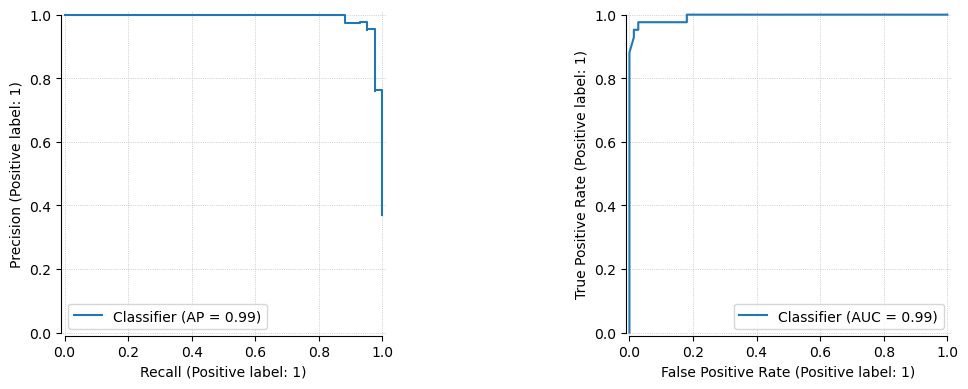

In [81]:
fig, axs = plt.subplots(figsize=(12,4), nrows=1, ncols=2)

PrecisionRecallDisplay.from_predictions(y_true=y_test, y_score=y_pred_forest_scores_test, ax=axs[0], despine=True)
RocCurveDisplay.from_predictions(y_true=y_test, y_score=y_pred_forest_scores_test, ax=axs[1], despine=True)

for ax in axs:
    ax.grid(True, linewidth=0.5, linestyle=":")
fig.tight_layout()

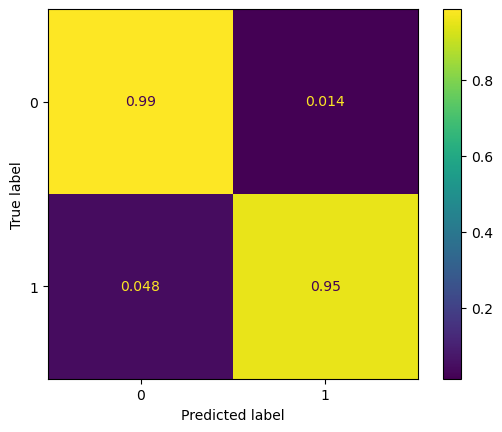

In [82]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_forest_test, normalize="true")